In [1]:
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

In [3]:
bundle = joblib.load("../data/processed/model_bundle.joblib")
model = bundle["model"]
cat_types = bundle["cat_types"]
sentinel_cols = bundle["sentinel_cols"]
drop_cols = bundle["drop_cols"]
cutoffs = bundle["cutoffs"]
cat_cols = list(cat_types)

In [4]:
def make_X(df):
    X = df.drop(columns=drop_cols).copy()
    for c in sentinel_cols:
        X[c] = X[c].where(X[c] >= 0)
    for c in cat_cols:
        X[c] = X[c].astype(cat_types[c])
    return X[model.feature_name_]

In [5]:
rules = {
    "고액 한도": lambda d: d["proposed_credit_limit"] >= 1900,
    "주거 BA": lambda d: d["housing_status"] == "BA",
    "windows": lambda d: d["device_os"] == "windows",
    "이름메일 유사도 낮음": lambda d: d["name_email_similarity"] < 0.18,
    "생년월일 메일 적음": lambda d: d["date_of_birth_distinct_emails_4w"] <= 4,
    "지점 방문 적음": lambda d: d["bank_branch_count_8w"] <= 1,
}


def eval_rule(df, flag):
    y = df["fraud_bool"] == 1
    old = df["customer_age"] >= 50
    tp = (flag & y).sum()
    fp = (flag & ~y).sum()
    return pd.Series({
        "flag_rate": flag.mean(),
        "precision": tp / flag.sum(),
        "recall": tp / y.sum(),
        "lift": (tp / flag.sum()) / y.mean(),
        "fp_per_1000": fp / len(df) * 1000,
        "fpr_50plus": (flag & ~y & old).sum() / (~y & old).sum(),
        "fpr_under50": (flag & ~y & ~old).sum() / (~y & ~old).sum(),
    })

In [6]:
files = ["Base", "Variant I", "Variant II", "Variant III", "Variant IV", "Variant V"]

monthly, summary, single_rows, combo_rows = {}, {}, {}, {}

for name in files:
    df = pd.read_csv(f"../data/raw/{name}.csv")
    monthly[name] = df.groupby("month")["fraud_bool"].mean()

    t = df[df["month"] >= 6]
    p = model.predict_proba(make_X(t))[:, 1]
    hits = pd.concat({k: f(t) for k, f in rules.items()}, axis=1).sum(axis=1)

    summary[name] = {
        "rows": len(t),
        "fraud_rate": t["fraud_bool"].mean(),
        "pr_auc": average_precision_score(t["fraud_bool"], p),
    }
    single_rows[name] = pd.DataFrame({k: eval_rule(t, f(t)) for k, f in rules.items()}).T

    cmp = {}
    for k, n in [("3개 이상", 3), ("2개 이상", 2)]:
        flag = hits >= n
        cut = np.quantile(p, 1 - flag.mean())
        cmp[f"룰 {k}"] = eval_rule(t, flag)
        cmp[f"모델 {k}"] = eval_rule(t, pd.Series(p >= cutoffs[k], index=t.index))
        cmp[f"모델 {k} 동일비율"] = eval_rule(t, pd.Series(p >= cut, index=t.index))
    combo_rows[name] = pd.DataFrame(cmp).T

In [7]:
pd.DataFrame(monthly).round(4)

,Base,Variant I,Variant II,Variant III,Variant IV,Variant V
month,,,,,,
0,0.0113,0.0113,0.0113,0.0117,0.0117,0.0117
1,0.0094,0.0094,0.0094,0.0089,0.0089,0.0089
2,0.0087,0.0087,0.0087,0.0073,0.0073,0.0073
3,0.0092,0.0092,0.0092,0.0136,0.0136,0.0136
4,0.0114,0.0114,0.0114,0.0157,0.0157,0.0157
5,0.0118,0.0118,0.0118,0.0091,0.0091,0.0091
6,0.0134,0.0134,0.0134,0.0123,0.0123,0.0123
7,0.0147,0.0147,0.0147,0.0093,0.0093,0.0093


In [8]:
pd.DataFrame(summary).T.round(4)

,rows,fraud_rate,pr_auc
Base,205011.0,0.014,0.1948
Variant I,205010.0,0.014,0.1814
Variant II,205010.0,0.014,0.2025
Variant III,241672.0,0.011,0.1278
Variant IV,241672.0,0.011,0.1278
Variant V,241672.0,0.011,0.1313


In [9]:
cols = ["flag_rate", "recall", "fp_per_1000", "fpr_50plus", "fpr_under50"]
rows = ["룰 3개 이상", "모델 3개 이상", "모델 3개 이상 동일비율"]
pd.concat({n: combo_rows[n].loc[rows, cols] for n in files}).round(4)

flag_rate  recall  fp_per_1000  fpr_50plus  \
Base        룰 3개 이상           0.0947  0.4583      88.2636      0.2032   
            모델 3개 이상          0.0834  0.6324      74.5521      0.1645   
            모델 3개 이상 동일비율     0.0947  0.6577      85.4637      0.1845   
Variant I   룰 3개 이상           0.0870  0.3951      81.4838      0.2075   
            모델 3개 이상          0.0779  0.5844      69.7088      0.1664   
            모델 3개 이상 동일비율     0.0870  0.6091      78.4791      0.1827   
Variant II  룰 3개 이상           0.1442  0.5782     136.0470      0.2074   
            모델 3개 이상          0.1211  0.7182     110.9848      0.1661   
            모델 3개 이상 동일비율     0.1442  0.7568     133.5398      0.1969   
Variant III 룰 3개 이상           0.1416  0.4823     136.3294      0.2067   
            모델 3개 이상          0.1191  0.6520     111.9782      0.1665   
            모델 3개 이상 동일비율     0.1416  0.6889     134.0619      0.1967   
Variant IV  룰 3개 이상           0.1416  0.4823     136.3294      0.2067   
            모델 3개 이상          0.1191  0.6520     111.9782      0.1665   
            모델 3개 이상 동일비율     0.1416  0.6889     134.0619      0.1967   
Variant V   룰 3개 이상           0.1408  0.4891     135.3984      0.2060   
            모델 3개 이상          0.1178  0.6535     110.6707      0.1642   
            모델 3개 이상 동일비율     0.1408  0.6953     133.1350      0.1951   

                           fpr_under50  
Base        룰 3개 이상             0.0675  
            모델 3개 이상            0.0584  
            모델 3개 이상 동일비율       0.0677  
Variant I   룰 3개 이상             0.0673  
            모델 3개 이상            0.0590  
            모델 3개 이상 동일비율       0.0669  
Variant II  룰 3개 이상             0.0684  
            모델 3개 이상            0.0589  
            모델 3개 이상 동일비율       0.0739  
Variant III 룰 3개 이상             0.0676  
            모델 3개 이상            0.0588  
            모델 3개 이상 동일비율       0.0731  
Variant IV  룰 3개 이상             0.0676  
            모델 3개 이상            0.0588  
            모델 3개 이상 동일비율       0.0731  
Variant V   룰 3개 이상             0.0663  
            모델 3개 이상            0.0585  
            모델 3개 이상 동일비율       0.0729

In [10]:
pd.DataFrame({n: single_rows[n]["lift"] for n in files}).round(2)

,Base,Variant I,Variant II,Variant III,Variant IV,Variant V
고액 한도,11.43,11.22,9.82,9.13,9.13,9.80
주거 BA,3.19,3.11,2.77,2.63,2.63,2.63
windows,2.26,2.21,2.21,2.04,2.04,2.05
이름메일 유사도 낮음,1.73,1.70,1.69,1.61,1.61,1.65
생년월일 메일 적음,1.53,1.15,1.54,1.14,1.14,1.18
지점 방문 적음,1.49,1.56,1.58,1.54,1.54,1.57


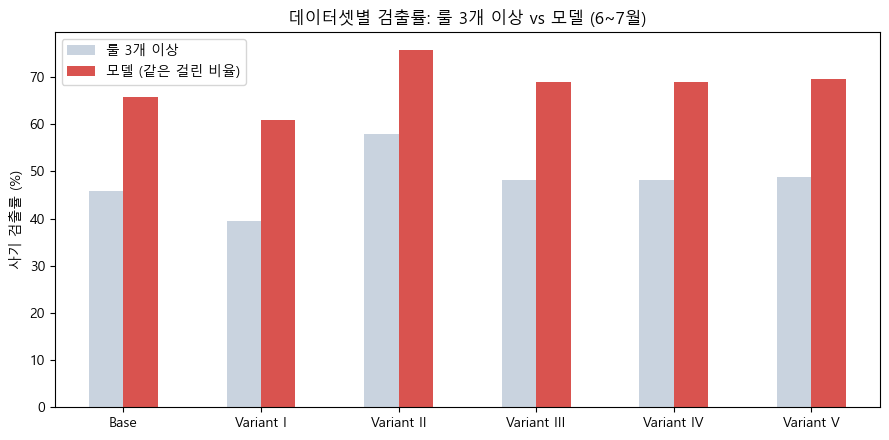

In [11]:
rec = pd.DataFrame({
    "룰 3개 이상": {n: combo_rows[n].loc["룰 3개 이상", "recall"] * 100 for n in files},
    "모델 (같은 걸린 비율)": {n: combo_rows[n].loc["모델 3개 이상 동일비율", "recall"] * 100 for n in files},
})

ax = rec.plot(kind="bar", figsize=(9, 4.5), color=["#c9d3df", "#d9534f"])
ax.set_xlabel("")
ax.set_ylabel("사기 검출률 (%)")
ax.set_title("데이터셋별 검출률: 룰 3개 이상 vs 모델 (6~7월)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/variant_recall.png", dpi=150)
plt.show()

In [12]:
pd.concat({n: combo_rows[n] for n in files}, names=["dataset", "method"]).reset_index().to_csv(
    "../results/variant_combo.csv", index=False)
pd.concat({n: single_rows[n] for n in files}, names=["dataset", "rule"]).reset_index().to_csv(
    "../results/variant_single.csv", index=False)

In [17]:
v3 = pd.read_csv("../data/raw/Variant III.csv")
v4 = pd.read_csv("../data/raw/Variant IV.csv")

In [18]:
common = [c for c in v4.columns if c in v3.columns]

t3 = v3[v3["month"] >= 6][common].reset_index(drop=True)
t4 = v4[v4["month"] >= 6][common].reset_index(drop=True)

diff = (t3 != t4).sum()
diff[diff > 0]

fraud_bool                            5256
income                              201511
name_email_similarity               241671
prev_address_months_count           104211
current_address_months_count        240216
customer_age                        185341
days_since_request                  241671
intended_balcon_amount              241671
payment_type                        167833
zip_count_4w                        241524
velocity_6h                         241671
velocity_24h                        241671
velocity_4w                         241671
bank_branch_count_8w                227723
date_of_birth_distinct_emails_4w    221066
employment_status                   110834
credit_risk_score                   240574
email_is_free                       120494
housing_status                      177767
phone_home_valid                    120148
phone_mobile_valid                   50614
bank_months_count                   212077
has_other_cards                      89856
proposed_cr

In [19]:
v3[common].equals(v4[common])

False

In [20]:
set(v3.columns) - set(v4.columns), set(v4.columns) - set(v3.columns)

({'x1', 'x2'}, set())

In [21]:
a = t3.sort_values(common).reset_index(drop=True)
b = t4.sort_values(common).reset_index(drop=True)
a.equals(b)

True